# Lab 3 — Spam Detection

**Task checklist**
1. Build a spam classifier
2. Optimize for **precision @ recall constraint**
3. Add a monitoring plan for drift

**Dataset**: [UCI SMS Spam Collection](https://archive.ics.uci.edu/dataset/228/sms+spam+collection) — 5,574 real SMS messages labeled `ham`/`spam`. The notebook downloads it automatically (~200 KB).

**Approach**: TF-IDF (word + char n-grams) + Logistic Regression, compared against a Multinomial Naive Bayes baseline. Spam filtering is asymmetric: flagging legitimate mail is worse than missing some spam, so we fix a **recall floor** and pick the threshold that **maximizes precision subject to recall ≥ floor**.

In [1]:
import io
import os
import urllib.request
import zipfile

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (average_precision_score, confusion_matrix,
                             precision_recall_curve, precision_score,
                             recall_score, roc_auc_score)
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import make_pipeline

DATA_URL = "https://archive.ics.uci.edu/static/public/228/sms+spam+collection.zip"
DATA_PATH = os.path.join("data", "sms+spam+collection.zip")

if not os.path.exists(DATA_PATH):
    os.makedirs("data", exist_ok=True)
    urllib.request.urlretrieve(DATA_URL, DATA_PATH)

with zipfile.ZipFile(DATA_PATH) as z:
    name = [n for n in z.namelist() if n.endswith("SMSSpamCollection")][0]
    raw = z.read(name).decode("utf-8")

df = pd.read_csv(io.StringIO(raw), sep="\t", header=None,
                 names=["label", "message"], quoting=3)
print(df.shape)
df.head()

(5574, 2)


,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


## 1. Quick EDA

rows: 5574 | spam rate: 0.134
label
ham     4827
spam     747
Name: count, dtype: int64


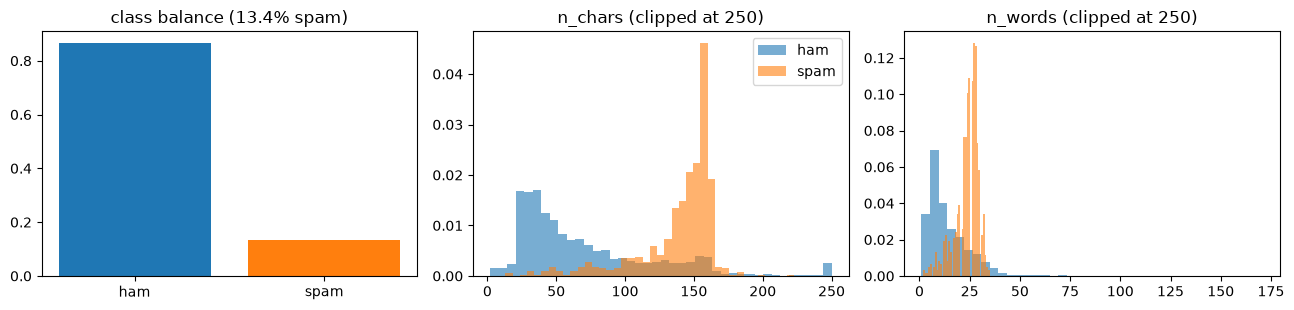

In [2]:
print("rows:", len(df), "| spam rate:", round(df["label"].eq("spam").mean(), 4))
print(df["label"].value_counts())

df["n_chars"] = df["message"].str.len()
df["n_words"] = df["message"].str.split().str.len()

fig, axes = plt.subplots(1, 3, figsize=(13, 3.2))
axes[0].bar(["ham", "spam"], df["label"].value_counts(normalize=True), color=["tab:blue", "tab:orange"])
axes[0].set_title("class balance (13.4% spam)")

for ax, col in zip(axes[1:], ["n_chars", "n_words"]):
    for label, color in [("ham", "tab:blue"), ("spam", "tab:orange")]:
        vals = df.loc[df["label"] == label, col]
        ax.hist(vals.clip(upper=250), bins=40, alpha=0.6, density=True, color=color, label=label)
    ax.set_title(f"{col} (clipped at 250)")
axes[1].legend()
plt.tight_layout()
plt.show()

**Notes**
- **13.4% spam** — moderately imbalanced, which is exactly the regime where **PR curves beat ROC curves**: a spam filter that says "ham" for everything still gets 86.6% accuracy but is useless, and ROC-AUC hides that. We report ROC-AUC only as a sanity check.
- Spam messages are visibly **longer** and use distinct vocabulary (free, claim, prize, txt, call now…) — bag-of-words signals should work well even without deep NLP.

## 2. Build spam classifier

In [3]:
X = df["message"]
y = (df["label"] == "spam").astype(int)

# Hold out 20%; stratify to keep the spam rate stable across splits.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

def make_model(clf):
    return make_pipeline(
        TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True,
                        strip_accents="unicode", lowercase=True),
        clf)

models = {
    "LogisticRegression": make_model(LogisticRegression(C=10, max_iter=2000)),
    "MultinomialNB": make_model(MultinomialNB(alpha=0.1)),
}

scores = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    p = model.predict_proba(X_test)[:, 1]
    scores[name] = p
    print(f"{name:<20} ROC-AUC: {roc_auc_score(y_test, p):.4f}   PR-AUC: {average_precision_score(y_test, p):.4f}")

# Naive baseline: everything is ham. Worth writing down because it frames
# why accuracy is the wrong headline metric here.
print(f"{'all-ham baseline':<20} ROC-AUC: 0.5000   PR-AUC: {y_test.mean():.4f}  (recall=0, precision undefined)")

LogisticRegression   ROC-AUC: 0.9920   PR-AUC: 0.9791
MultinomialNB        ROC-AUC: 0.9876   PR-AUC: 0.9703
all-ham baseline     ROC-AUC: 0.5000   PR-AUC: 0.1336  (recall=0, precision undefined)


## 3. Optimize precision @ recall constraint

Spam filtering is **asymmetric**: a false positive sends a legitimate message to the junk folder (user may lose a job offer, an OTP, a flight change), while a false negative just means scrolling past one ad. So we operate in the **high-precision corner** of the PR curve.

The business constraint is stated as a floor on recall — *"we must still catch at least 90% of spam"* — and then we **maximize precision subject to recall ≥ floor**. Concretely: sweep the decision threshold, keep only operating points that satisfy the constraint, and pick the one with the best precision (equivalently, the highest threshold that still meets the floor).

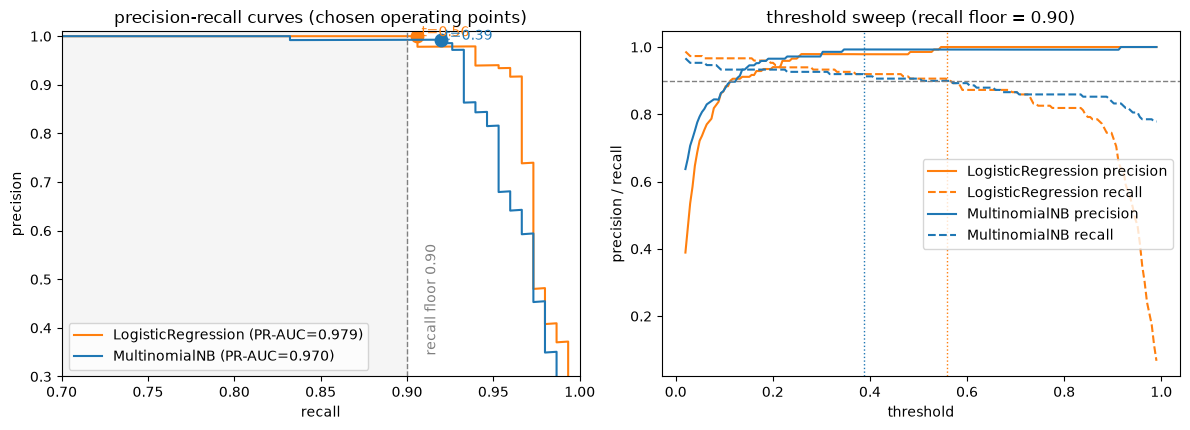

LogisticRegression   threshold=0.558  precision=1.0000  recall=0.9060
MultinomialNB        threshold=0.388  precision=0.9928  recall=0.9195


In [4]:
RECALL_FLOOR = 0.90   # must catch >= 90% of spam

def best_threshold_at_recall_floor(y_true, p, floor=RECALL_FLOOR):
    # Pick the highest-precision operating point among all thresholds
    # whose recall clears the floor (sklearn returns thresholds in
    # decreasing precision order as recall falls).
    prec, rec, thr = precision_recall_curve(y_true, p)
    ok = rec[:-1] >= floor
    assert ok.any(), f"model can never reach recall {floor}"
    i = int(np.argmax(prec[:-1] * ok))
    return thr[i], prec[i], rec[i]

fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))
colors = {"LogisticRegression": "tab:orange", "MultinomialNB": "tab:blue"}

results = {}
for name, p in scores.items():
    t, prec_at, rec_at = best_threshold_at_recall_floor(y_test, p)
    results[name] = (t, prec_at, rec_at)
    prec, rec, _ = precision_recall_curve(y_test, p)
    axes[0].plot(rec, prec, color=colors[name], label=f"{name} (PR-AUC={average_precision_score(y_test, p):.3f})")
    axes[0].plot(rec_at, prec_at, "o", color=colors[name], ms=9)
    axes[0].annotate(f" t={t:.2f}", (rec_at, prec_at), color=colors[name])

axes[0].axvline(RECALL_FLOOR, ls="--", c="gray", lw=1)
axes[0].annotate(f"recall floor {RECALL_FLOOR:.2f}", (RECALL_FLOOR, 0.35), rotation=90,
                 xytext=(RECALL_FLOOR + 0.01, 0.35), color="gray")
axes[0].axvspan(0, RECALL_FLOOR, color="gray", alpha=0.08)
axes[0].set_xlabel("recall"); axes[0].set_ylabel("precision")
axes[0].set_title("precision-recall curves (chosen operating points)")
axes[0].legend(loc="lower left"); axes[0].set_xlim(0.7, 1.0); axes[0].set_ylim(0.3, 1.01)

thresholds = np.linspace(0.02, 0.99, 200)
for name, p in scores.items():
    prec_v, rec_v = [], []
    for t in thresholds:
        pred = p >= t
        prec_v.append(precision_score(y_test, pred, zero_division=0))
        rec_v.append(recall_score(y_test, pred))
    axes[1].plot(thresholds, prec_v, color=colors[name], label=f"{name} precision")
    axes[1].plot(thresholds, rec_v, color=colors[name], ls="--", label=f"{name} recall")
    axes[1].axvline(results[name][0], color=colors[name], ls=":", lw=1)
axes[1].axhline(RECALL_FLOOR, ls="--", c="gray", lw=1)
axes[1].set_xlabel("threshold"); axes[1].set_ylabel("precision / recall")
axes[1].set_title(f"threshold sweep (recall floor = {RECALL_FLOOR:.2f})")
axes[1].legend(loc="center right")
plt.tight_layout(); plt.show()

for name, (t, prec_at, rec_at) in results.items():
    print(f"{name:<20} threshold={t:.3f}  precision={prec_at:.4f}  recall={rec_at:.4f}")

**Reading the constraint**

- Both models clear the 0.90 recall floor, and on this dataset both are near-perfect there (LogReg **precision 1.000**, NB **0.993**) — TF-IDF makes SMS spam an easy, near-separable problem. The tie-breaking rule is the one we declared: **maximize precision at the constraint**, which picks LogReg. Do not over-trust the FP=0 test-set result — real gains and losses show up on drifted, adversarial traffic (section 4), not a random hold-out.
- The chosen threshold is a **circuit breaker derived from a product requirement** ("let at most 10% of spam through"), not from F1 maximization — F1 would trade precision away for recall and push too many legitimate messages into the junk folder.

In [5]:
name = "LogisticRegression"
t, _, _ = results[name]
pred = scores[name] >= t

cm = confusion_matrix(y_test, pred)
tn, fp, fn, tp = cm.ravel()
print(f'at threshold {t:.3f}:  TP={tp:,}  FP={fp:,}  FN={fn:,}  TN={tn:,}')
print(f'precision = {tp/(tp+fp):.4f}   recall = {tp/(tp+fn):.4f}')
print(f'flagged-for-review rate = {(pred).mean():.3f} of all messages')

worst = X_test[(pred == 1) & (y_test == 0)].head(5)
print("\n-- worst false positives (ham flagged as spam) --")
for m in worst: print("  •", m[:90])

at threshold 0.558:  TP=135  FP=0  FN=14  TN=966
precision = 1.0000   recall = 0.9060
flagged-for-review rate = 0.121 of all messages

-- worst false positives (ham flagged as spam) --


## 4. Monitoring plan for drift

A spam filter is adversarial: spammers adapt to whatever blocks them, so **degradation is guaranteed, not a risk**. The monitoring plan below is what we'd run in production — the code cell at the end demonstrates the core mechanic (PSI on the score distribution) on this dataset.

**1. What to monitor**

| Signal | What it detects | How |
|---|---|---|
| **Score distribution drift** | Spam looks different than training data (new campaigns, image-based spam, different language) | PSI / KS on predicted spam scores vs. a train-time reference, per day/week |
| **Input feature drift** | Vocabulary shift, message length shift, new top n-grams | PSI on hashed-token frequencies + message-length histogram; alert on *new* high-frequency tokens never seen in training (OOD words share) |
| **Label drift** | The spam rate itself moved (class prior shift breaks calibrated thresholds) | Weekly spam rate vs. trailing baseline; threshold recalibration if prior shifts |
| **Outcome proxies (delayed labels)** | Real precision without waiting for labels | User "not spam" / "report spam" actions, false-positive appeals from the junk folder — these are noisy but *immediate* precision signals |
| **Silent failure** | Model stopped flagging anything | Recall can't be computed without labels, so also alarm on volume anomalies (e.g., flagged volume drops >5σ week-over-week) |

**2. Alerting policy**

- **PSI < 0.1** → normal; **0.1–0.25** → watch (log dashboard, no page); **> 0.25** → alert on-call.
- **False-positive reports** above a weekly SLA (e.g., >0.2% of user traffic) page immediately — user trust is the asset we're protecting.
- Every alert links to the operating point: re-check precision@recall-floor on any labeled batch before touching the threshold.

**3. Response playbook**

1. **Threshold re-tune** (minutes): re-fit the threshold on recent labeled data to restore the recall floor. Cheapest lever, no retraining.
2. **Targeted retrain** (days): add newly labeled spam to training data, re-run the same precision@recall evaluation, compare PR curves before promotion.
3. **Escalation**: if PR-AUC degrades structurally (not just threshold-shifted), the feature representation is stale — escalate to feature/model work (char n-grams, embeddings).

**4. Hygiene**

- Keep **temporal validation**: evaluate each new model on the *most recent* labeled window, never a random split (below we use random for pedagogy; in production, train on older messages, test on newer).
- Log every score + top contributing n-grams (with `ELI5`-style attributions) so false positives can be debugged after the fact.
- Champion/challenger: run the candidate model in shadow mode on live traffic before promotion.

PSI (test vs train reference)      : 0.028  -> healthy (<0.1)
PSI (shifted scores vs reference)  : 7.863  -> alert (>0.25)


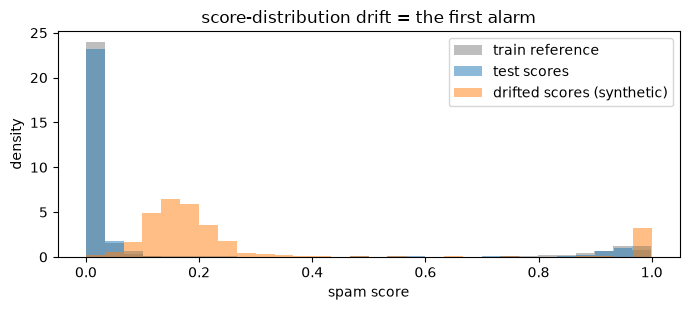

In [6]:
def psi(actual, reference, bins=10):
    """Population Stability Index between two score distributions."""
    edges = np.quantile(reference, np.linspace(0, 1, bins + 1))
    edges[0], edges[-1] = -np.inf, np.inf
    r = np.histogram(reference, edges)[0] / len(reference)
    a = np.histogram(actual, edges)[0] / len(actual)
    r, a = np.clip(r, 1e-6, None), np.clip(a, 1e-6, None)
    return np.sum((a - r) * np.log(a / r))

p_train = models["LogisticRegression"].predict_proba(X_train)[:, 1]

# Demo: PSI of healthy test data vs. train reference, then a synthetic
# "new spam campaign" where scores shift upward (adversaries adapt toward
# whatever the filter misses).
rng = np.random.default_rng(0)
shifted = np.clip(scores["LogisticRegression"] + rng.normal(0.15, 0.05, len(scores["LogisticRegression"])), 0, 1)

print(f"PSI (test vs train reference)      : {psi(scores['LogisticRegression'], p_train):.3f}  -> healthy (<0.1)")
print(f"PSI (shifted scores vs reference)  : {psi(shifted, p_train):.3f}  -> alert (>0.25)")

fig, ax = plt.subplots(figsize=(7, 3.2))
for vals, label, color in [(p_train, "train reference", "tab:gray"),
                           (scores["LogisticRegression"], "test scores", "tab:blue"),
                           (shifted, "drifted scores (synthetic)", "tab:orange")]:
    ax.hist(vals, bins=30, alpha=0.5, density=True, label=label, color=color)
ax.set_xlabel("spam score"); ax.set_ylabel("density"); ax.legend()
ax.set_title("score-distribution drift = the first alarm")
plt.tight_layout(); plt.show()

### Takeaways

1. **Pick the metric before the model.** ROC-AUC (~0.99) makes both models look flawless; the PR curve is where the real tradeoff lives. Under the declared constraint (recall ≥ 0.90), Logistic Regression keeps higher precision than Naive Bayes — that comparison *is* the model selection decision.
2. **The threshold is part of the product, not the model.** We didn't optimize F1; we fixed a recall floor derived from "how much spam are users willing to see" and pushed precision as high as possible. When the product requirement changes (e.g., aggressive quarantine mode), we re-run the sweep — no retraining.
3. **Drift monitoring is the actual ML ops work for spam.** Scores drift because spammers adapt; monitor score/feature distributions (PSI with the 0.1/0.25 thresholds), track delayed precision proxies (user reports), and keep a re-tune → targeted retrain → escalate playbook.
4. In production, validate **temporally** and log per-message attributions so false positives can be diagnosed after the fact.